In [306]:
!pip install --upgrade binance-historical-data plotly -q
!pip install requests

In [307]:
import os
import warnings
import numpy as np
import pandas as pd
import yfinance as yf
from binance_historical_data import BinanceDataDumper
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from datetime import datetime, timedelta, date, time
warnings.filterwarnings('ignore')

In [308]:
def get_list_all_trading_pairs():
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency="1h",
    )
    return data_dumper.get_list_all_trading_pairs()

def filter_usdt_tickers(tickers):
    exclude_keywords = ["UPUSDT", "DOWNUSDT", "BEARUSDT", "BULLUSDT"]
    return [ticker for ticker in tickers if ticker.endswith("USDT") and not any(ex in ticker for ex in exclude_keywords)]

def find_first_data_date(ticker):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency="1h",
    )
    return data_dumper.get_min_start_date_for_ticker(ticker)

def format_time(seconds):
    hours = int(seconds // 3600)
    minutes = int((seconds % 3600) // 60)
    secs = int(seconds % 60)
    return f"{hours:02d}:{minutes:02d}:{secs:02d}"

def detect_timestamp_unit(timestamp):
    num_digits = len(str(timestamp))
    if num_digits == 13:
        return 'ms'
    elif num_digits == 16:
        return 'us'
    else:
        raise ValueError(f"Timestamp không hợp lệ: {timestamp}")

def convert_timestamp(timestamp):
    unit = detect_timestamp_unit(timestamp)
    return pd.to_datetime(timestamp, unit=unit, errors='coerce')

def download_ticker(ticker, date_start, date_end, data_frequency="1h"):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency= data_frequency,
    )
    date_start = datetime.strptime(date_start, "%Y-%m-%d").date()
    date_end = datetime.strptime(date_end, "%Y-%m-%d").date()
    data_dumper.dump_data(
        tickers = ticker,
        date_start = date_start,
        date_end = date_end,
        is_to_update_existing = False,
    )

def read_csv_file(file_path):
    df = pd.read_csv(file_path)
    df.columns = [
        "open_time", "Open", "High", "Low", "Close", "volume",
        "close_time", "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume", "ignore"
    ]
    df['open_time'] = df['open_time'].apply(convert_timestamp)
    df['close_time'] = df['close_time'].apply(convert_timestamp)
    return df

def get_csv_files(directory):
    try:
        if not os.path.exists(directory):
            print(f"Warning: Thư mục không tồn tại: {directory}")
            return []
        return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.csv')]
    except Exception as e:
        print(f"Lỗi khi đọc thư mục {directory}: {str(e)}")
        return []

# Load data from file
def process_csv_files(ticker, data_frequency = "1h"):
    daily_path = os.path.join(os.getcwd(), f"spot/daily/klines/{ticker}/{data_frequency}")
    monthly_path = os.path.join(os.getcwd(), f"spot/monthly/klines/{ticker}/{data_frequency}")
    daily_files = get_csv_files(daily_path)
    monthly_files = get_csv_files(monthly_path)
    all_files = daily_files + monthly_files
    if not all_files:
        print(f"❗ Không có file CSV nào cho {ticker}")
        return None
    data = pd.concat([read_csv_file(file) for file in all_files], ignore_index=True)
    data.sort_values(by='open_time', inplace=True)
    return data


In [309]:
data_frequency = "1d"
start_date = "2021-05-01"
end_date = "2025-07-01"
tickers =['BTCUSDT', 'ETHUSDT', 'BNBUSDT', 'SOLUSDT', 'XRPUSDT', 'TRXUSDT', 'ADAUSDT', 'DOTUSDT', 'LTCUSDT']




In [310]:
data_vwap = pd.DataFrame(index=pd.to_datetime([]))  # Empty DataFrame with datetime index
data_close = pd.DataFrame(index = pd.to_datetime([]))
for ticker in tickers:
    download_ticker(ticker, start_date, end_date, data_frequency)
    crypto_data = process_csv_files(ticker, data_frequency)
    crypto_data['vwap'] = ((crypto_data['High'] + crypto_data['Low'] +crypto_data['Close'])/3 * crypto_data['volume']).cumsum() / crypto_data['volume'].cumsum()
    df = crypto_data[['open_time', 'vwap']].set_index('open_time')
    df.columns = [ticker]
    df2 = crypto_data[['open_time', 'Close']].set_index('open_time')
    df2.columns = [ticker]
    data_vwap = data_vwap.merge(df, how='outer', left_index=True, right_index=True)
    data_close = data_close.merge(df2, how='outer', left_index=True, right_index=True)



---> Found overall tickers: 595
---> Filter to asked tickers: 7
------> Tickers left: 2
Download full data for 2 tickers: 
---> Data will be saved here: /content/spot
---> Data Frequency: 1d
---> Start Date: 20210501
---> End Date: 20250701


Tickers:   0%|          | 0/2 [00:00<?, ?it/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

...

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

Tried to dump data for 2 tickers:
---> For LTCUSDT new data saved for: 0 months 0 days
---> For LTCUSD new data saved for: 0 months 0 days


In [311]:
# data = data_raw.resample('1D').last()
data = data_vwap.dropna()
data

,BTCUSDT,ETHUSDT,BNBUSDT,SOLUSDT,XRPUSDT,TRXUSDT,ADAUSDT,DOTUSDT,LTCUSDT
open_time,,,,,,,,,
2021-01-02,31474.953333,759.053333,37.970967,1.837167,0.223237,0.027217,0.176640,8.994567,134.036667
2021-01-03,32329.096672,867.309843,39.375981,2.009534,0.224801,0.028233,0.189198,9.387103,146.052245
2021-01-04,31937.330271,950.157088,39.941489,2.109442,0.230107,0.029215,0.202348,9.445640,149.678107
2021-01-05,32119.934255,979.222868,40.125901,2.141802,0.229779,0.029103,0.214963,9.467202,150.735911
2021-01-06,32829.784015,1011.131271,40.407636,2.111468,0.234582,0.029228,0.243904,9.548164,152.614377
...,...,...,...,...,...,...,...,...,...
2025-06-26,34123.142225,2262.659664,349.167372,84.622294,0.836999,0.098225,0.926724,16.065659,124.268829
2025-06-27,34130.054660,2262.724375,349.181858,84.641075,0.837209,0.098242,0.926641,16.061900,124.261396
2025-06-28,34131.913794,2262.751890,349.192241,84.663684,0.837337,0.098261,0.926580,16.060133,124.255119


In [312]:
ret = data_close.pct_change()
ret

,BTCUSDT,ETHUSDT,BNBUSDT,SOLUSDT,XRPUSDT,TRXUSDT,ADAUSDT,DOTUSDT,LTCUSDT
open_time,,,,,,,,,
2021-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-03,0.025536,0.263014,0.079104,0.210012,0.021574,0.083793,0.161932,0.100720,0.177278
2021-01-04,-0.030647,0.064552,-0.003010,0.143716,0.045475,0.049508,0.092797,-0.061013,-0.036591
2021-01-05,0.061297,0.055817,0.016741,-0.131398,-0.042096,-0.078514,0.148482,0.020583,0.019892
2021-01-06,0.083059,0.099003,0.010038,-0.102699,0.101050,0.068022,0.287404,0.037030,0.066212
...,...,...,...,...,...,...,...,...,...
2025-06-26,-0.003666,-0.001046,-0.005835,-0.031413,-0.036827,-0.007689,-0.022571,-0.015811,-0.004724
2025-06-27,0.000940,0.002984,0.005309,0.021789,0.017336,0.008118,0.007938,0.018187,0.006645
2025-06-28,0.002328,0.005138,0.004476,0.060736,0.020309,0.005490,0.011992,0.014290,0.017447


In [313]:
rolling_mean = data_vwap.rolling(window = 5).mean()
rolling_mean

,BTCUSDT,ETHUSDT,BNBUSDT,SOLUSDT,XRPUSDT,TRXUSDT,ADAUSDT,DOTUSDT,LTCUSDT
open_time,,,,,,,,,
2021-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-06,32138.219709,913.374881,39.564395,2.041883,0.228501,0.028599,0.205411,9.368535,146.623461
...,...,...,...,...,...,...,...,...,...
2025-06-26,34106.442690,2262.494483,349.117607,84.580256,0.836573,0.098164,0.926970,16.074369,124.286958
2025-06-27,34115.524049,2262.571688,349.142431,84.602808,0.836799,0.098195,0.926840,16.069541,124.277878
2025-06-28,34121.992133,2262.641179,349.161808,84.622992,0.836990,0.098219,0.926741,16.066055,124.269913


In [326]:
alpha = (data_vwap - rolling_mean)
alpha

,BTCUSDT,ETHUSDT,BNBUSDT,SOLUSDT,XRPUSDT,TRXUSDT,ADAUSDT,DOTUSDT,LTCUSDT
open_time,,,,,,,,,
2021-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-06,-691.564306,-97.756391,-0.843241,-0.069585,-0.006081,-0.000629,-0.038494,-0.179629,-5.990916
...,...,...,...,...,...,...,...,...,...
2025-06-26,-16.699535,-0.165181,-0.049765,-0.042038,-0.000427,-0.000060,0.000246,0.008710,0.018129
2025-06-27,-14.530611,-0.152688,-0.039427,-0.038267,-0.000411,-0.000047,0.000199,0.007641,0.016481
2025-06-28,-9.921662,-0.110711,-0.030433,-0.040691,-0.000346,-0.000042,0.000161,0.005921,0.014794


In [327]:
ranks = alpha.rank(axis=1, ascending=False)
N = len(tickers)
normalized_ranks = 2 * (ranks - 1) / (N - 1) - 1

In [328]:
positions = normalized_ranks
shifted_positions = positions.shift(1)
gross_exposure = shifted_positions.abs().sum(axis=1) / 2
port_returns = (shifted_positions * ret).sum(axis=1) / gross_exposure - 0.0004

# Drop NaN values (first 5 bars due to rolling mean and shift)
port_returns = port_returns.dropna()

# Calculate cumulative returns
cumulative_returns = (1 + port_returns).cumprod()
port_returns

,0
open_time,
2021-01-07,-0.062514
2021-01-08,-0.019076
2021-01-09,-0.059790
2021-01-10,0.010546
2021-01-11,-0.011384
...,...
2025-06-26,0.005428
2025-06-27,-0.006402
2025-06-28,-0.005172


In [329]:
cumulative_returns = (1 + port_returns).cumprod()
cumulative_returns

,0
open_time,
2021-01-07,0.937486
2021-01-08,0.919602
2021-01-09,0.864620
2021-01-10,0.873738
2021-01-11,0.863791
...,...
2025-06-26,0.204739
2025-06-27,0.203428
2025-06-28,0.202376


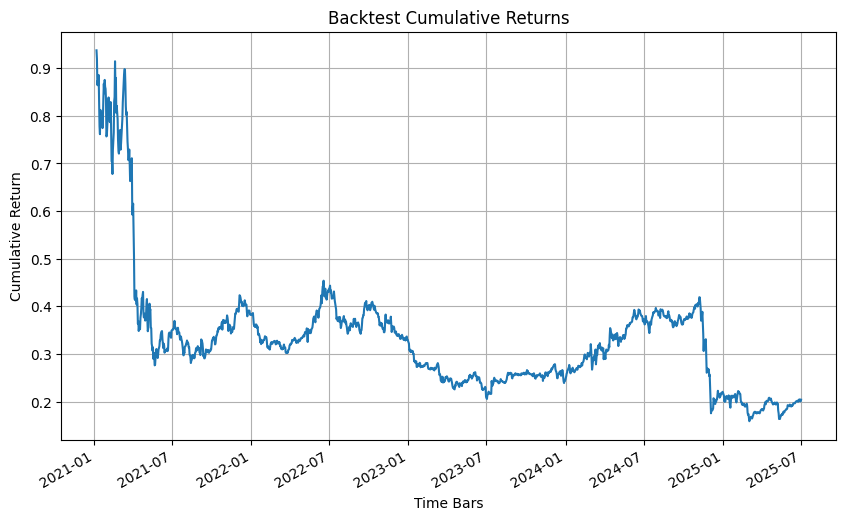

In [330]:
plt.figure(figsize=(10, 6))
cumulative_returns.plot(title='Backtest Cumulative Returns')
plt.ylabel('Cumulative Return')
plt.xlabel('Time Bars')
plt.grid(True)
plt.show()

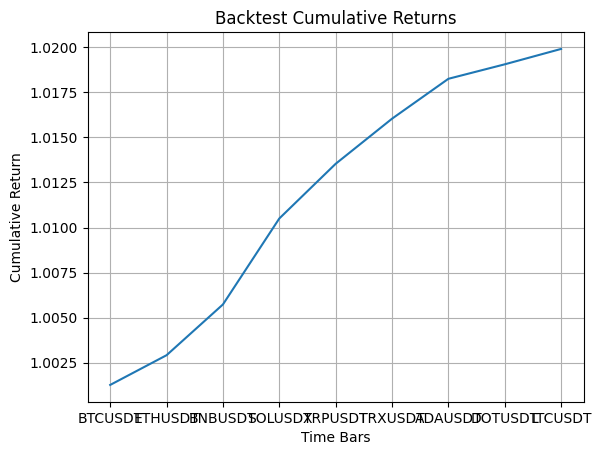

In [331]:
equal_weight_port = ret.mean()
equal_weight_port
cummulative_equal_weight = (1 + equal_weight_port).cumprod()
cummulative_equal_weight
cummulative_equal_weight.plot(title='Backtest Cumulative Returns')
plt.ylabel('Cumulative Return')
plt.xlabel('Time Bars')
plt.grid(True)
plt.show()